In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
from utils import get_data, get_rc_and_err

In [3]:
NOM_FILE   = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_notrueptcons.root'
HAD_FILE   = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_hadcorr05_notrueptcons.root'
TOW_FILE   = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_tow104_notrueptcons.root'
EFF_FILE   = '/gpfs01/star/pwg/youqi/run12/final_0628/results_20235003/matched/all050124_rc_eff096_notrueptcons.root'

COLUMNS    = ['pt', 'b', 'w', 'pts', 'bs', 'ws']

PT_EDGES   = [15, 20, 25, 30, 40, 60]
PT_CENTERS = [17.5, 22.5, 27.5, 35, 50]
PT_XERR    = [2.5, 2.5, 2.5, 5, 10]

plt.rcParams['font.size'] = 12

In [4]:
def bin_df_in_pts(df):
    return [df[(df.pts > PT_EDGES[i]) & (df.pts < PT_EDGES[i+1])] for i in range(5)]

def get_rc_and_err_arr(df_arr, ob):
    rc_arr, err_arr = [], []
    for df in df_arr:
        rc, err = get_rc_and_err(df, ob)
        rc_arr.append(rc)
        err_arr.append(err)
    return rc_arr, err_arr

In [5]:
query = 'pts>15 and bs!=-9 and w<1'
df_nom     = get_data(COLUMNS, NOM_FILE, 'MatchedTree').query(query)
df_hadcorr = get_data(COLUMNS, HAD_FILE, 'MatchedTree').query(query)
df_tow104  = get_data(COLUMNS, TOW_FILE, 'MatchedTree').query(query)
df_eff096  = get_data(COLUMNS, EFF_FILE, 'MatchedTree').query(query)

In [6]:
rc_nom,     err_nom     = get_rc_and_err_arr(bin_df_in_pts(df_nom),     'bs')
rc_hadcorr, err_hadcorr = get_rc_and_err_arr(bin_df_in_pts(df_hadcorr), 'bs')
rc_tow104,  err_tow104  = get_rc_and_err_arr(bin_df_in_pts(df_tow104),  'bs')
rc_eff096,  err_eff096  = get_rc_and_err_arr(bin_df_in_pts(df_eff096),  'bs')

print('nom range:')
print('  lower:', np.asarray(rc_nom) - np.asarray(err_nom))
print('  upper:', np.asarray(rc_nom) + np.asarray(err_nom))
print('hadcorr:', rc_hadcorr)
print('tow104: ', rc_tow104)
print('eff096: ', rc_eff096)

nom range:
  lower: [-0.3487169  -0.35085375 -0.35407069 -0.35888008 -0.36221506]
  upper: [-0.34352925 -0.34640491 -0.34798881 -0.35125991 -0.34566643]
hadcorr: [-0.34613186721564176, -0.3465046503682098, -0.34992026266677684, -0.3515749459809804, -0.35093295101287797]
tow104:  [-0.34579806112065603, -0.34785250970738457, -0.3490012043004887, -0.3521912440129387, -0.3575146665191358]
eff096:  [-0.34473329782599554, -0.34801137203721577, -0.34920152337043586, -0.3552904959134854, -0.3606461075520774]


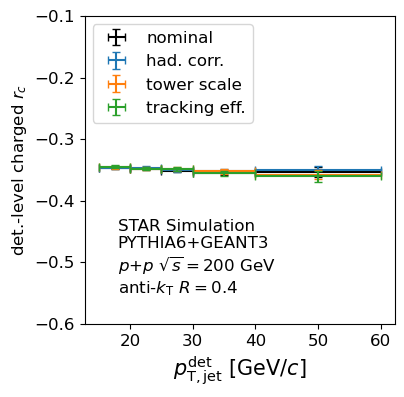

In [7]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.errorbar(PT_CENTERS, rc_nom,     xerr=PT_XERR, yerr=err_nom,     capsize=3, color='k', ls='none', label='nominal')
ax.errorbar(PT_CENTERS, rc_hadcorr, xerr=PT_XERR, yerr=err_hadcorr, capsize=3,            ls='none', label='had. corr.')
ax.errorbar(PT_CENTERS, rc_tow104,  xerr=PT_XERR, yerr=err_tow104,  capsize=3,            ls='none', label='tower scale')
ax.errorbar(PT_CENTERS, rc_eff096,  xerr=PT_XERR, yerr=err_eff096,  capsize=3,            ls='none', label='tracking eff.')
ax.text(18, -0.55, 'STAR Simulation\nPYTHIA6+GEANT3\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ $R = 0.4$')
ax.set_xlabel(r'$p_{\mathrm{T,jet}}^{\mathrm{det}}$ [GeV$/c$]', fontsize=15)
ax.set_ylabel('det.-level charged $r_c$')
ax.set_ylim(-0.6, -0.1)
ax.legend(loc='upper left')
plt.show()